# Task 1 (1.1–1.4): teoría de colas, simulador y validación
CC2017 Modelación y Simulación, UVG · Hoja de Trabajo 7 · Grupo 5.
Este notebook contiene los cálculos teóricos (1.1), la referencia al código original generado por IA (1.2), su auditoría (1.3) y la validación del simulador corregido (1.4).
La lógica reutilizable está en `src/hospital_uci/` (`teoria.py`, `simulador.py`); aquí solo se llama y se grafica. Se ejecuta de arriba abajo (~6 min).

Unidades: tiempos en **días** (se convierten a **horas** al reportar W y Wq), tasas en 1/día.

In [1]:
import subprocess, hashlib
import sys, json, pathlib, math
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RAIZ = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from hospital_uci import teoria as T, simulador as S, sir

FIG, DAT = RAIZ / "resultados" / "figuras", RAIZ / "resultados" / "datos"
FIG.mkdir(parents=True, exist_ok=True); DAT.mkdir(parents=True, exist_ok=True)
AZUL, NARANJA, GRIS = "#0072B2", "#D55E00", "#6b7280"      # azul/naranja: distinguibles con daltonismo
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6, "font.size": 10,
                     "axes.titlesize": 11, "legend.frameon": False})
P = T.parametros_grupo(5)
lam, mu, c = P["lam"], P["mu"], P["c"]
RES = {}      # resultados numéricos de este notebook (se guardan en JSON al final)

def md_tabla(nombre, df, **kw):
    return df

## Parámetros del grupo 5
$\lambda = 3.0+0.2((g-1)\bmod 5)$, $c = 17+((g-1)\bmod 3)$, $a=\lambda/\mu$, $\rho = a/c$, $k_{off}=\lceil c-a\rceil+3$, $\beta = 0.30+0.02((g-1)\bmod 4)$, con $\mu=0.25$/día.

In [2]:
P = T.parametros_grupo(5)
lam, mu, c = P["lam"], P["mu"], P["c"]
esperado = dict(lam=3.8, c=18, a=15.2, k_off=6, beta=0.30)
assert math.isclose(P["lam"], 3.8) and P["c"] == 18 and math.isclose(P["a"], 15.2)
assert math.isclose(P["rho"], 0.8444, abs_tol=5e-5) and P["k_off"] == 6 and math.isclose(P["beta"], 0.30)
RES["parametros"] = P
pd.DataFrame([{"g": P["g"], "λ (pac/día)": P["lam"], "μ (1/día)": P["mu"], "c (camas)": P["c"], "a = λ/μ": P["a"],
               "ρ = a/c": round(P["rho"], 4), "k_off (camas)": P["k_off"], "β (1/día)": P["beta"]}])

,g,λ (pac/día),μ (1/día),c (camas),a = λ/μ,ρ = a/c,k_off (camas),β (1/día)
0,5,3.8,0.25,18,15.2,0.8444,6,0.3


## Task 1.1 — Teoría de colas
**M/M/c con espera** ($a<c$):
$a=\lambda/\mu$, $\rho=a/c$, $B(c,a)$ por recurrencia, $C(c,a)=\dfrac{B}{1-\rho(1-B)}$ (Erlang C), $L_q=C\,\dfrac{\rho}{1-\rho}$, $W_q=L_q/\lambda$, $W=W_q+1/\mu$, $L=L_q+a$.

**M/M/c/c sin espera:** $B(0,a)=1$, $B(k,a)=\dfrac{aB(k-1,a)}{k+aB(k-1,a)}$; $\lambda_{ef}=\lambda(1-B)$; camas ocupadas $L=\lambda_{ef}/\mu=a(1-B)$; $W=1/\mu$.

In [3]:
# Recurrencia de Erlang B paso a paso (a = 15.2)
b, filas = 1.0, [(0, 1.0)]
for k in range(1, c + 1):
    b = P["a"] * b / (k + P["a"] * b); filas.append((k, b))
rec = pd.DataFrame(filas, columns=["k", "B(k, 15.2)"])
assert math.isclose(b, T.erlang_b(c, P["a"])) and math.isclose(b, T.erlang_b_directa(c, P["a"]), rel_tol=1e-12)
md_tabla("recurrencia_erlang_b", rec.round({"B(k, 15.2)": 6}))
rec.round(6).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
k,0.0,1.000000,2.000000,3.000000,4.000000,5.000000,6.000000,7.000000,8.000000,9.000000,10.000000,11.00000,12.000000,13.000000,14.000000,15.000000,16.000000,17.000000,18.000000
"B(k, 15.2)",1.0,0.938272,0.877012,0.816296,0.756212,0.696867,0.638388,0.580926,0.524661,0.469804,0.416604,0.36535,0.316368,0.270024,0.226706,0.186812,0.150723,0.118759,0.091145


In [4]:
M, B = T.mmc(lam, mu, c), T.mmcc(lam, mu, c)
RES["teoria_con_espera"], RES["teoria_sin_espera"] = M, B
sust = pd.DataFrame([
 ["a = λ/μ", f"3.8/0.25", M["a"], "camas"],
 ["ρ = a/c", f"15.2/18", M["rho"], "—"],
 ["C(c,a) (Erlang C)", f"B/(1-ρ(1-B)) = {B['p_bloqueo']:.5f}/(1-{M['rho']:.4f}·{1-B['p_bloqueo']:.5f})", M["p_esperar"], "prob."],
 ["Lq = C·ρ/(1-ρ)", f"{M['p_esperar']:.5f}·{M['rho']:.4f}/{1-M['rho']:.4f}", M["Lq"], "pacientes"],
 ["Wq = Lq/λ", f"{M['Lq']:.5f}/3.8 = {M['Wq']:.5f} d", M["Wq_h"], "horas"],
 ["W = Wq + 1/μ", f"{M['Wq']:.5f} + 4 d", M["W_h"], "horas"],
 ["L = Lq + a", f"{M['Lq']:.5f} + 15.2", M["L"], "pacientes"]], columns=["Medida (con espera)", "Sustitución", "Valor", "Unidad"])
md_tabla("teoria_con_espera", sust.round({"Valor": 4}))
sust2 = pd.DataFrame([
 ["B(c,a) (Erlang B, recurrencia)", "B(18, 15.2)", B["p_bloqueo"], "prob."],
 ["λ_ef = λ(1-B)", f"3.8·(1-{B['p_bloqueo']:.5f})", B["lam_efectiva"], "pac/día"],
 ["L = λ_ef/μ = a(1-B)", f"{B['lam_efectiva']:.5f}/0.25", B["L"], "camas ocupadas"],
 ["Utilización por cama = L/c", f"{B['L']:.4f}/18", B["utilizacion"], "—"],
 ["W = 1/μ", "1/0.25 d", B["W_h"], "horas"]], columns=["Medida (sin espera)", "Sustitución", "Valor", "Unidad"])
md_tabla("teoria_sin_espera", sust2.round({"Valor": 5}))
display(sust.round(4)); display(sust2.round(5))

,Medida (con espera),Sustitución,Valor,Unidad
0,a = λ/μ,3.8/0.25,15.2000,camas
1,ρ = a/c,15.2/18,0.8444,—
2,"C(c,a) (Erlang C)",B/(1-ρ(1-B)) = 0.09115/(1-0.8444·0.90885),0.3920,prob.
3,Lq = C·ρ/(1-ρ),0.39198·0.8444/0.1556,2.1279,pacientes
4,Wq = Lq/λ,2.12791/3.8 = 0.55998 d,13.4395,horas
5,W = Wq + 1/μ,0.55998 + 4 d,109.4395,horas
6,L = Lq + a,2.12791 + 15.2,17.3279,pacientes


,Medida (sin espera),Sustitución,Valor,Unidad
0,"B(c,a) (Erlang B, recurrencia)","B(18, 15.2)",0.09115,prob.
1,λ_ef = λ(1-B),3.8·(1-0.09115),3.45365,pac/día
2,L = λ_ef/μ = a(1-B),3.45365/0.25,13.81459,camas ocupadas
3,Utilización por cama = L/c,13.8146/18,0.76748,—
4,W = 1/μ,1/0.25 d,96.00000,horas


In [5]:
# Ley de Little
lc  = T.little(M["L"], lam, M["W"]);  lcq = T.little(M["Lq"], lam, M["Wq"])
ls  = T.little(B["L"], B["lam_efectiva"], B["W"]);  ls_mal = T.little(B["L"], lam, B["W"])
little_teo = pd.DataFrame([
  ["Con espera: L = λ·W", lc["L"], lc["lam_W"], lc["error_relativo"]],
  ["Con espera: Lq = λ·Wq", lcq["L"], lcq["lam_W"], lcq["error_relativo"]],
  ["Sin espera: L = λ_ef·W", ls["L"], ls["lam_W"], ls["error_relativo"]],
  ["Sin espera (ERROR): L vs λ·W con λ nominal", ls_mal["L"], ls_mal["lam_W"], ls_mal["error_relativo"]]],
  columns=["Verificación", "L (o Lq)", "λ·W (o λ·Wq)", "Error relativo"])
RES["little_teoria"] = little_teo.to_dict("records")
md_tabla("little_teoria", little_teo.round({"L (o Lq)": 5, "λ·W (o λ·Wq)": 5, "Error relativo": 6}))
print("Usar λ en vez de λ_ef sobrestima L por el factor 1/(1-B) =", round(1/(1-B["p_bloqueo"]), 4),
      "(error relativo B/(1-B) =", round(B["p_bloqueo"]/(1-B["p_bloqueo"]), 4), ")")
little_teo

Usar λ en vez de λ_ef sobrestima L por el factor 1/(1-B) = 1.1003 (error relativo B/(1-B) = 0.1003 )


,Verificación,L (o Lq),λ·W (o λ·Wq),Error relativo
0,Con espera: L = λ·W,17.327913,17.327913,2.050284e-16
1,Con espera: Lq = λ·Wq,2.127913,2.127913,0.000000e+00
2,Sin espera: L = λ_ef·W,13.814594,13.814594,0.000000e+00
3,Sin espera (ERROR): L vs λ·W con λ nominal,13.814594,15.200000,1.002857e-01


## Task 1.2 — Primera versión generada por IA (solo se referencia, NO se importa)
El código original está en `anexo/B_simulador_original_ia.py`, congelado (solo lectura) y con hash en `anexo/SHA256SUMS.txt`.
Se verifica que sigue idéntico a como se archivó:

In [6]:
reg = dict(l.split("  ")[::-1] for l in (RAIZ / "anexo" / "SHA256SUMS.txt").read_text().strip().splitlines())
h_actual = hashlib.sha256((RAIZ / "anexo" / "B_simulador_original_ia.py").read_bytes()).hexdigest()
print("hash registrado:", reg["B_simulador_original_ia.py"]); print("hash actual    :", h_actual)
assert h_actual == reg["B_simulador_original_ia.py"], "¡el original fue modificado!"

hash registrado: c3ade4551b6455e25080c843b6c75cf69b1aa5bedf50d91464ab4ad29e173118
hash actual    : c3ade4551b6455e25080c843b6c75cf69b1aa5bedf50d91464ab4ad29e173118


## Task 1.3 — Auditoría del original y pruebas
(a) Se importa el original (`anexo/B_simulador_original_ia.py`) **sin modificarlo** y se prueba con casos D/D/c calculados a mano
(solo se sustituye, dentro del módulo importado, el generador aleatorio por uno cuyo `expovariate(r)` devuelve $1/r$), además de comparaciones estadísticas.
(b) Se corre la batería `pytest` del simulador corregido.

In [7]:
import importlib.util, types
spec = importlib.util.spec_from_file_location("orig", RAIZ / "anexo" / "B_simulador_original_ia.py")
orig = importlib.util.module_from_spec(spec); spec.loader.exec_module(orig)

class RngFalso:
    """Generador de prueba: expovariate(r) = 1/r  ->  sistema determinista D/D/c."""
    def __init__(self, seed=None): pass
    def expovariate(self, rate): return 1.0 / rate

def correr_orig_det(**kw):
    real = orig.random
    orig.random = types.SimpleNamespace(Random=RngFalso)
    try: return orig.simulate(**kw)
    finally: orig.random = real

det = lambda v: (lambda rng: v)     # gancho del simulador corregido: valor constante
filas = []
def fila(caso, medida, esperado, original, corregido):
    filas.append({"caso": caso, "medida": medida, "esperado": esperado, "original": original, "corregido": corregido})

# A: 1 cama, llegadas cada 2, servicio 0.5, H=101 -> L = 25/101
o = correr_orig_det(lam=0.5, mu=2.0, c=1, horizon=101.0, warmup=0.0, seed=0)
n = S.simular(0.5, 2.0, 1, 101.0, 0.0, semilla=0, interarribo=det(2.0), servicio=det(0.5))
fila("A: D/D/1 (gap 2, serv 0.5), H=101", "L", 25 / 101, o["L"], n["L"])
fila("A: D/D/1 (gap 2, serv 0.5), H=101", "utilizacion", 25 / 101, o["utilizacion"], n["utilizacion"])
# B: con calentamiento 11 -> L = 22.5/90
o = correr_orig_det(lam=0.5, mu=2.0, c=1, horizon=101.0, warmup=11.0, seed=0)
n = S.simular(0.5, 2.0, 1, 101.0, 11.0, semilla=0, interarribo=det(2.0), servicio=det(0.5))
fila("B: igual con calentamiento 11", "L", 22.5 / 90, o["L"], n["L"])
# C: cola creciente: gap 1, serv 2, H=10.5
o = correr_orig_det(lam=1.0, mu=0.5, c=1, horizon=10.5, warmup=0.0, seed=0)
n = S.simular(1.0, 0.5, 1, 10.5, 0.0, semilla=0, interarribo=det(1.0), servicio=det(2.0))
fila("C: D/D/1 (gap 1, serv 2), H=10.5", "Wq (desde llegada, sin censura)", 4.5, o["Wq"], n["Wq"])
fila("C: D/D/1 (gap 1, serv 2), H=10.5", "p_esperar", 0.9, o["p_esperar"], n["p_esperar"])
fila("C: D/D/1 (gap 1, serv 2), H=10.5", "L", 32 / 10.5, o["L"], n["L"])
fila("C: D/D/1 (gap 1, serv 2), H=10.5", "Lq", 22.5 / 10.5, o["Lq"], n["Lq"])
# D: pérdida pura: gap 1, serv 1.5, H=10.2 -> bloqueo 0.5
o = correr_orig_det(lam=1.0, mu=1 / 1.5, c=1, horizon=10.2, warmup=0.0, seed=0, wait=False)
n = S.simular(1.0, 1 / 1.5, 1, 10.2, 0.0, semilla=0, con_espera=False, interarribo=det(1.0), servicio=det(1.5))
fila("D: D/D/1/1 (gap 1, serv 1.5), H=10.2", "p_bloqueo", 0.5, o["p_bloqueo"], n["p_bloqueo"])
fila("D: D/D/1/1 (gap 1, serv 1.5), H=10.2", "L (camas ocupadas)", 7.2 / 10.2, o["L"], n["L"])
# E: empate salida/llegada: gap 2, serv 2, 1 cama, sin espera -> bloqueo 0
o = correr_orig_det(lam=0.5, mu=0.5, c=1, horizon=21.0, warmup=0.0, seed=0, wait=False)
n = S.simular(0.5, 0.5, 1, 21.0, 0.0, semilla=0, con_espera=False, interarribo=det(2.0), servicio=det(2.0))
fila("E: D/D/1/1 con empate (gap 2, serv 2), H=21", "p_bloqueo", 0.0, o["p_bloqueo"], n["p_bloqueo"])

# F: sesgo por censura con carga alta y horizonte corto (lam=5 > c*mu=4.5), 2000 réplicas cada uno
NF = 2000
oo = [orig.simulate(5.0, 0.25, 18, 30.0, 0.0, seed=200000 + i) for i in range(NF)]
nn = S.replicar(NF, 31337, lam=5.0, mu=0.25, c=18, horizonte=30.0, calentamiento=0.0)
for clave, nombre in [("Wq", "Wq (días)"), ("Lq", "Lq (control)"), ("L", "L (control)")]:
    a = np.array([r[clave] for r in oo]); b = np.array([r[clave] for r in nn])
    se = float(np.sqrt(a.var(ddof=1) / NF + b.var(ddof=1) / NF))
    fila(f"F: sobrecarga λ=5, c=18, H=30 ({NF} réplicas c/u)", f"{nombre}, media; EE de la diferencia={se:.3f}", None,
         float(a.mean()), float(b.mean()))

# G: autocorrelación lag-1 de L entre réplicas del original (semillas consecutivas)
oo2 = [orig.simulate(3.8, 0.25, 18, 100.0, 10.0, seed=5000 + i) for i in range(300)]
x = np.array([r["L"] for r in oo2]); r1 = float(np.corrcoef(x[:-1], x[1:])[0, 1])

# H: el original ejecutado tal cual (30 réplicas, H=2000, calentamiento 200, semillas 1000..1029)
res_esp = orig.replicate(lam, mu, c, 2000, 200, wait=True)
res_sin = orig.replicate(lam, mu, c, 2000, 200, wait=False)
teo_esp, teo_sin = T.mmc(lam, mu, c), T.mmcc(lam, mu, c)
def tabla_orig(res, teo, solo):
    return [{"medida": k, "teoria": teo[k], "media": res[k][0], "ic_inf": res[k][1], "ic_sup": res[k][2],
             "contiene_teoria": bool(res[k][1] <= teo[k] <= res[k][2])} for k in solo]
orig_main = {"con_espera": tabla_orig(res_esp, teo_esp, ["L", "Lq", "Wq", "utilizacion", "p_esperar"]),
             "sin_espera": tabla_orig(res_sin, teo_sin, ["L", "utilizacion", "p_bloqueo"])}
AUD = {"filas": filas, "autocorr_lag1_L_original": r1, "original_main": orig_main}
aud = pd.DataFrame(filas)
aud["OK original"] = [("—" if pd.isna(e) else ("sí" if abs(o_ - e) < 1e-9 else "NO")) for e, o_ in zip(aud["esperado"], aud["original"])]
RES["auditoria_original"] = AUD
print("autocorrelación lag-1 de L entre réplicas del original (semillas consecutivas):", round(r1, 3))
print("El original, ejecutado tal cual: ¿la teoría cae en el IC?",
      {k["medida"]: k["contiene_teoria"] for k in orig_main["con_espera"] + orig_main["sin_espera"]})
aud.round(6)

autocorrelación lag-1 de L entre réplicas del original (semillas consecutivas): 0.027
El original, ejecutado tal cual: ¿la teoría cae en el IC? {'L': True, 'Lq': True, 'Wq': True, 'utilizacion': True, 'p_esperar': True, 'p_bloqueo': True}


,caso,medida,esperado,original,corregido,OK original
0,"A: D/D/1 (gap 2, serv 0.5), H=101",L,0.247525,0.247525,0.247525,sí
1,"A: D/D/1 (gap 2, serv 0.5), H=101",utilizacion,0.247525,0.247525,0.247525,sí
2,B: igual con calentamiento 11,L,0.250000,0.250000,0.250000,sí
3,"C: D/D/1 (gap 1, serv 2), H=10.5","Wq (desde llegada, sin censura)",4.500000,2.000000,4.500000,NO
4,"C: D/D/1 (gap 1, serv 2), H=10.5",p_esperar,0.900000,0.900000,0.900000,sí
5,"C: D/D/1 (gap 1, serv 2), H=10.5",L,3.047619,3.047619,3.047619,sí
6,"C: D/D/1 (gap 1, serv 2), H=10.5",Lq,2.142857,2.142857,2.142857,sí
7,"D: D/D/1/1 (gap 1, serv 1.5), H=10.2",p_bloqueo,0.500000,0.500000,0.500000,sí
8,"D: D/D/1/1 (gap 1, serv 1.5), H=10.2",L (camas ocupadas),0.705882,0.705882,0.705882,sí
9,"E: D/D/1/1 con empate (gap 2, serv 2), H=21",p_bloqueo,0.000000,0.500000,0.000000,NO


In [8]:
p = subprocess.run([sys.executable, "-m", "pytest", "-q", "-p", "no:cacheprovider"], capture_output=True, text=True, cwd=RAIZ)
print(p.stdout[-600:]); RES["pytest"] = p.stdout.strip().splitlines()[-1]; assert p.returncode == 0

.......................                                                  [100%]
23 passed in 1.45s



## Task 1.4 — Validación con réplicas independientes
### Elección de calentamiento y horizonte (promedio móvil, método de Welch)
Réplicas **independientes de las de validación** (semillas maestras 5001 y 5002), arranque con el hospital vacío, muestreo de la longitud de cola cada día,
promedio entre 200 réplicas y promedio móvil centrado de ventana ±10 días. Para la variante sin espera la cola es siempre 0, así que se grafica el número de pacientes en el sistema.

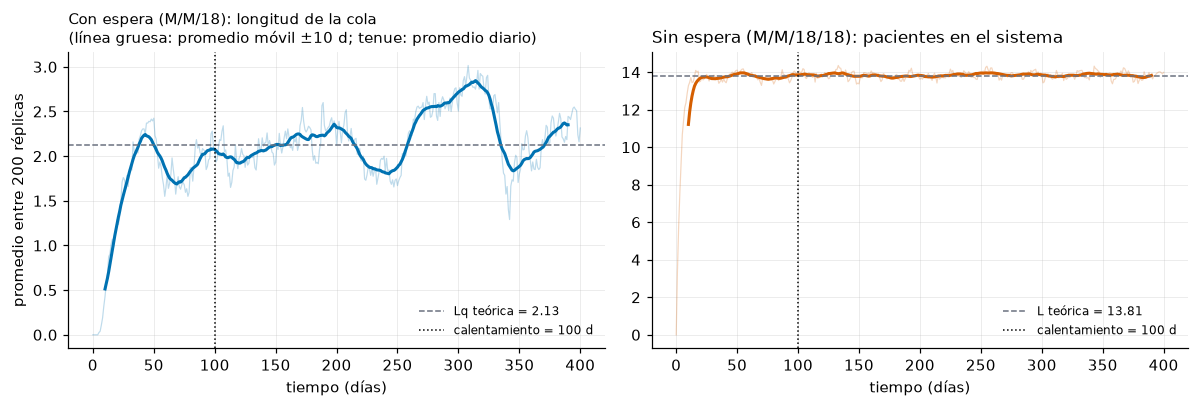

EE medio del promedio móvil (con espera, t>=100): 0.276 = 12 % de la meseta empírica 2.26
Con espera (Lq):


,bloque (días),dif. media vs meseta,EE,|dif|/EE,sesgado (>2 EE)
0,0–50,-0.886,0.200,4.438,SÍ
1,50–100,-0.388,0.239,1.627,no
2,100–150,-0.248,0.248,1.000,no
3,150–200,-0.045,0.256,0.175,no


Sin espera (pacientes en el sistema):


,bloque (días),dif. media vs meseta,EE,|dif|/EE,sesgado (>2 EE)
0,0–50,-1.176,0.062,18.907,SÍ
1,50–100,-0.072,0.071,1.009,no
2,100–150,0.026,0.070,0.367,no
3,150–200,-0.054,0.065,0.827,no


In [9]:
SEM_WELCH = {"con_espera": 5001, "sin_espera": 5002}
NW, HW, W = 200, 400, 10
rw_e = S.replicar(NW, SEM_WELCH["con_espera"], lam=lam, mu=mu, c=c, horizonte=HW, calentamiento=0.0, muestreo_dt=1.0)
rw_s = S.replicar(NW, SEM_WELCH["sin_espera"], lam=lam, mu=mu, c=c, horizonte=HW, calentamiento=0.0, muestreo_dt=1.0, con_espera=False)
Qe = np.mean([r["traza"]["cola"] for r in rw_e], axis=0)
Ns = np.mean([r["traza"]["sistema"] for r in rw_s], axis=0)
t = rw_e[0]["traza"]["t"]
ma = lambda x: np.convolve(x, np.ones(2 * W + 1) / (2 * W + 1), mode="valid")
tm = t[W:-W]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a_, y, ym, teo, tit, col, lab in [(ax[0], Qe, ma(Qe), M["Lq"], "Con espera (M/M/18): longitud de la cola", AZUL, "Lq teórica"),
                                      (ax[1], Ns, ma(Ns), B["L"], "Sin espera (M/M/18/18): pacientes en el sistema", NARANJA, "L teórica")]:
    a_.plot(t, y, color=col, alpha=0.25, lw=0.8); a_.plot(tm, ym, color=col, lw=2)
    a_.axhline(teo, color=GRIS, ls="--", lw=1, label=f"{lab} = {teo:.2f}")
    a_.axvline(100, color="k", lw=1, ls=":", label="calentamiento = 100 d"); a_.legend(loc="lower right", fontsize=8)
    a_.set_xlabel("tiempo (días)"); a_.set_title(tit, loc="left")
ax[0].set_ylabel("promedio entre 200 réplicas"); ax[0].set_title("Con espera (M/M/18): longitud de la cola\n(línea gruesa: promedio móvil ±10 d; tenue: promedio diario)", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(FIG / "fig_1_4_welch_promedio_movil.png", dpi=160); plt.show()
# Diagnóstico del transitorio SIN usar la teoría. Primer intento (criterio fijado antes de ver los datos): "el promedio móvil se mantiene a ±15 % de la meseta".
# Falló por RUIDO, no por transitorio: el error estándar del promedio móvil entre réplicas es ~13 % de Lq (ver tabla), del mismo tamaño que la banda.
# Criterio con ruido explícito: promedio por bloques de 50 d, comparado de forma PAREADA (por réplica) con la meseta (media en t >= 200 d); se marca el bloque si |dif| > 2 EE.
def bloques(Y, ancho=50, ini_meseta=200):
    plano = Y[:, ini_meseta:].mean(1); filas = []
    for a in range(0, ini_meseta, ancho):
        d = Y[:, a:a + ancho].mean(1) - plano
        filas.append({"bloque (días)": f"{a}–{a+ancho}", "dif. media vs meseta": d.mean(), "EE": d.std(ddof=1) / math.sqrt(len(d)),
                      "|dif|/EE": abs(d.mean()) / (d.std(ddof=1) / math.sqrt(len(d))), "sesgado (>2 EE)": "SÍ" if abs(d.mean()) > 2 * d.std(ddof=1) / math.sqrt(len(d)) else "no"})
    return pd.DataFrame(filas), plano.mean()
Qm = np.array([r["traza"]["cola"] for r in rw_e]); Nm = np.array([r["traza"]["sistema"] for r in rw_s])
bl_e, pl_e = bloques(Qm); bl_s, pl_s = bloques(Nm)
ee_ma = np.array([np.convolve(q, np.ones(2 * W + 1) / (2 * W + 1), mode="valid") for q in Qm]).std(0, ddof=1)[tm >= 100].mean() / math.sqrt(NW)
print(f"EE medio del promedio móvil (con espera, t>=100): {ee_ma:.3f} = {100*ee_ma/pl_e:.0f} % de la meseta empírica {pl_e:.2f}")
print("Con espera (Lq):"); display(bl_e.round(3)); print("Sin espera (pacientes en el sistema):"); display(bl_s.round(3))
md_tabla("welch_bloques_con_espera", bl_e.round(3)); md_tabla("welch_bloques_sin_espera", bl_s.round(3))
WARMUP = 100.0
assert (bl_e[bl_e["bloque (días)"].str.split("–").str[0].astype(int) >= WARMUP]["sesgado (>2 EE)"] == "no").all()
assert (bl_s[bl_s["bloque (días)"].str.split("–").str[0].astype(int) >= WARMUP]["sesgado (>2 EE)"] == "no").all()
te_, ts_ = float("nan"), float("nan")
RES["welch"] = {"semillas_maestras": SEM_WELCH, "replicas": NW, "ventana_dias": W, "bloques_con_espera": bl_e.to_dict("records"), "bloques_sin_espera": bl_s.to_dict("records"), "ee_ma_rel": ee_ma / pl_e, "criterio_inicial_pm15pct": "fallo por ruido (t~353 d en con espera); reemplazado por criterio de bloques con 2 EE", "calentamiento_elegido": WARMUP}

In [10]:
# Horizonte: regla fijada de antemano = que el semiancho del IC 95 % de Lq (30 réplicas) sea <= 5 % de la media; se estima con un piloto (semilla maestra 5003, H=2000)
HP = 2000.0
piloto = S.replicar(30, 5003, lam=lam, mu=mu, c=c, horizonte=HP, calentamiento=WARMUP)
ic = S.ic_t([r["Lq"] for r in piloto]); rel = ic["semiancho"] / ic["media"]
H_req = WARMUP + (HP - WARMUP) * (rel / 0.05) ** 2
HORIZONTE = float(math.ceil(H_req / 500) * 500)
print(f"piloto: Lq = {ic['media']:.3f} ± {ic['semiancho']:.3f} ({100*rel:.1f} %). Horizonte requerido ≈ {H_req:.0f} d -> H = {HORIZONTE:.0f} d")
RES["horizonte"] = {"piloto_semilla": 5003, "piloto_H": HP, "semiancho_rel_piloto": rel, "H_requerido": H_req, "H_elegido": HORIZONTE}

piloto: Lq = 2.108 ± 0.257 (12.2 %). Horizonte requerido ≈ 11366 d -> H = 11500 d


In [11]:
NREP = 30
SEM_VAL = {"con_espera": 5004, "sin_espera": 5005}
rv_e = S.replicar(NREP, SEM_VAL["con_espera"], lam=lam, mu=mu, c=c, horizonte=HORIZONTE, calentamiento=WARMUP)
rv_s = S.replicar(NREP, SEM_VAL["sin_espera"], lam=lam, mu=mu, c=c, horizonte=HORIZONTE, calentamiento=WARMUP, con_espera=False)
sem = pd.DataFrame({"réplica": range(1, NREP + 1), "estado semilla con espera": [r["semilla_estado"] for r in rv_e],
                    "estado semilla sin espera": [r["semilla_estado"] for r in rv_s]})
sem.to_csv(DAT / "semillas_validacion.csv", index=False)
RES["semillas"] = {"maestra_con_espera": 5004, "maestra_sin_espera": 5005, "n_replicas": NREP, "horizonte": HORIZONTE, "calentamiento": WARMUP,
                   "estados_con_espera": sem["estado semilla con espera"].tolist(), "estados_sin_espera": sem["estado semilla sin espera"].tolist()}
print("Semillas maestras:", SEM_VAL, "| réplica i usa SeedSequence(maestra).spawn(30)[i]; estados primeros 5 (con espera):", sem["estado semilla con espera"].head(5).tolist())

def tabla_val(reps, teo, medidas):
    res = S.resumir(reps, claves=tuple(k for k, *_ in medidas)); filas = []
    for k, nombre, f in medidas:
        r_ = res[k]; tv = teo[k] * f if teo[k] is not None else None
        lo, hi, m = r_["ic_inf"] * f, r_["ic_sup"] * f, r_["media"] * f
        filas.append({"Medida": nombre, "Teoría": tv, "Media simulada": m, "IC 95 % inf": lo, "IC 95 % sup": hi,
                      "¿Teoría dentro?": "sí" if lo <= tv <= hi else "NO", "Semiancho rel. (%)": 100 * r_["semiancho"] * f / m if m else float("nan")})
    return pd.DataFrame(filas)
MED_E = [("L", "L (pacientes en sistema)", 1), ("Lq", "Lq (pacientes en cola)", 1), ("Wq", "Wq (horas)", 24), ("W", "W (horas)", 24),
         ("utilizacion", "Utilización ρ", 1), ("p_esperar", "P(esperar) = Erlang C", 1), ("lam_efectiva", "Tasa de ingresos (pac/día)", 1)]
MED_S = [("L", "L = camas ocupadas", 1), ("utilizacion", "Utilización por cama", 1), ("p_bloqueo", "P(bloqueo) = Erlang B", 1),
         ("lam_efectiva", "Tasa efectiva de ingresos (pac/día)", 1), ("W", "W (horas)", 24)]
tv_e, tv_s = tabla_val(rv_e, M, MED_E), tabla_val(rv_s, B, MED_S)
RES["validacion_con_espera"], RES["validacion_sin_espera"] = tv_e.to_dict("records"), tv_s.to_dict("records")
md_tabla("validacion_con_espera", tv_e.round(4)); md_tabla("validacion_sin_espera", tv_s.round(4))
print("VARIANTE CON ESPERA (M/M/18)"); display(tv_e.round(4)); print("VARIANTE SIN ESPERA (M/M/18/18)"); display(tv_s.round(4))

Semillas maestras: {'con_espera': 5004, 'sin_espera': 5005} | réplica i usa SeedSequence(maestra).spawn(30)[i]; estados primeros 5 (con espera): [2586245558, 3264494469, 1183481016, 3068021181, 1211284958]
VARIANTE CON ESPERA (M/M/18)


,Medida,Teoría,Media simulada,IC 95 % inf,IC 95 % sup,¿Teoría dentro?,Semiancho rel. (%)
0,L (pacientes en sistema),17.3279,17.2550,17.1440,17.3660,sí,0.6433
1,Lq (pacientes en cola),2.1279,2.0834,2.0011,2.1656,sí,3.9477
2,Wq (horas),13.4395,13.1676,12.6583,13.6768,sí,3.8675
3,W (horas),109.4395,109.0697,108.4729,109.6665,sí,0.5472
4,Utilización ρ,0.8444,0.8429,0.8408,0.8449,sí,0.2445
5,P(esperar) = Erlang C,0.3920,0.3893,0.3831,0.3956,sí,1.6056
6,Tasa de ingresos (pac/día),3.8000,3.7966,3.7904,3.8028,sí,0.1636


VARIANTE SIN ESPERA (M/M/18/18)


,Medida,Teoría,Media simulada,IC 95 % inf,IC 95 % sup,¿Teoría dentro?,Semiancho rel. (%)
0,L = camas ocupadas,13.8146,13.8068,13.7861,13.8275,sí,0.1498
1,Utilización por cama,0.7675,0.7670,0.7659,0.7682,sí,0.1498
2,P(bloqueo) = Erlang B,0.0911,0.0913,0.0903,0.0923,sí,1.0903
3,Tasa efectiva de ingresos (pac/día),3.4536,3.4500,3.4447,3.4552,sí,0.1530
4,W (horas),96.0000,96.0459,95.9164,96.1755,sí,0.1349


In [12]:
# Ley de Little con medidas SIMULADAS (independiente de la teoría): L vs λ_ef·W y Lq vs λ_ef·Wq, replica a réplica y sobre las medias
def little_sim(reps, con_cola):
    out = {}
    e1 = np.array([abs(r["L"] - r["lam_efectiva"] * r["W"]) / r["L"] for r in reps])
    out["L = λ_ef·W: error relativo por réplica (media)"] = e1.mean()
    m = lambda k: np.mean([r[k] for r in reps])
    out["L = λ_ef·W: error relativo de las medias"] = abs(m("L") - m("lam_efectiva") * m("W")) / m("L")
    if con_cola:
        e2 = np.array([abs(r["Lq"] - r["lam_efectiva"] * r["Wq"]) / r["Lq"] for r in reps])
        out["Lq = λ_ef·Wq: error relativo por réplica (media)"] = e2.mean()
        out["Lq = λ_ef·Wq: error relativo de las medias"] = abs(m("Lq") - m("lam_efectiva") * m("Wq")) / m("Lq")
    else:  # error de usar λ nominal en vez de λ_ef
        out["ERROR (usar λ nominal): |L - λ·W|/L de las medias"] = abs(m("L") - lam * m("W")) / m("L")
    out["valores: L, λ_ef (pac/día), W (días)"] = (m("L"), m("lam_efectiva"), m("W"))
    return out
LS_e, LS_s = little_sim(rv_e, True), little_sim(rv_s, False)
RES["little_sim_con_espera"], RES["little_sim_sin_espera"] = LS_e, LS_s
tl = pd.DataFrame([{"Variante": "con espera", "Verificación": k, "Valor": v if not isinstance(v, tuple) else ", ".join(f"{x:.4f}" for x in v)} for k, v in LS_e.items()] +
                  [{"Variante": "sin espera", "Verificación": k, "Valor": v if not isinstance(v, tuple) else ", ".join(f"{x:.4f}" for x in v)} for k, v in LS_s.items()])
md_tabla("little_simulacion", tl.assign(Valor=tl["Valor"].map(lambda v: f"{v:.3e}" if isinstance(v, float) else v)))
tl

,Variante,Verificación,Valor
0,con espera,L = λ_ef·W: error relativo por réplica (media),0.000214
1,con espera,L = λ_ef·W: error relativo de las medias,0.000066
2,con espera,Lq = λ_ef·Wq: error relativo por réplica (media),0.000157
3,con espera,Lq = λ_ef·Wq: error relativo de las medias,0.000181
4,con espera,"valores: L, λ_ef (pac/día), W (días)","17.2550, 3.7966, 4.5446"
5,sin espera,L = λ_ef·W: error relativo por réplica (media),0.000129
6,sin espera,L = λ_ef·W: error relativo de las medias,0.000029
7,sin espera,ERROR (usar λ nominal): |L - λ·W|/L de las medias,0.101432
8,sin espera,"valores: L, λ_ef (pac/día), W (días)","13.8068, 3.4500, 4.0019"


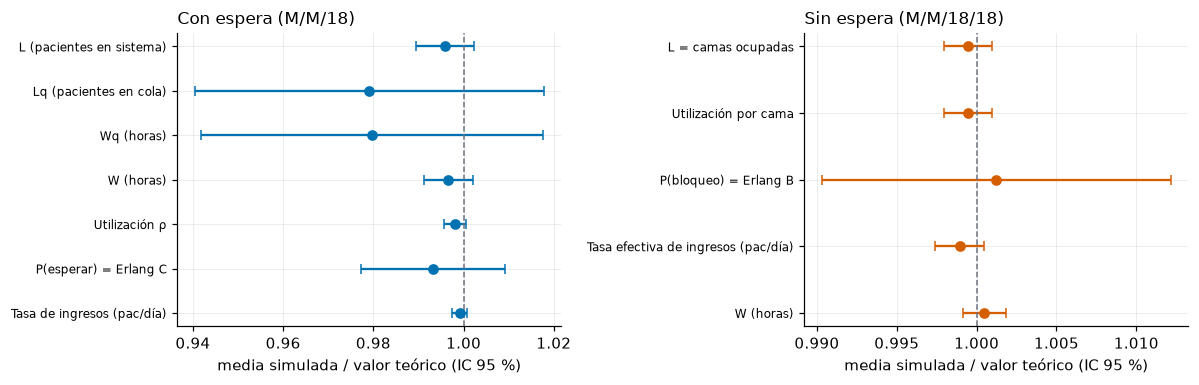

In [13]:
# Gráfica de validación: teoría vs media simulada con IC 95 %, normalizando cada medida por su valor teórico
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
for a_, tv, tit, col in [(ax[0], tv_e, "Con espera (M/M/18)", AZUL), (ax[1], tv_s, "Sin espera (M/M/18/18)", NARANJA)]:
    y = np.arange(len(tv))[::-1]; r_ = lambda c_: tv[c_] / tv["Teoría"]
    a_.errorbar(r_("Media simulada"), y, xerr=[r_("Media simulada") - r_("IC 95 % inf"), r_("IC 95 % sup") - r_("Media simulada")], fmt="o", color=col, capsize=3, lw=1.5)
    a_.axvline(1, color=GRIS, ls="--", lw=1); a_.set_yticks(y); a_.set_yticklabels(tv["Medida"], fontsize=8)
    a_.set_xlabel("media simulada / valor teórico (IC 95 %)"); a_.set_title(tit, loc="left")
plt.tight_layout(); plt.savefig(FIG / "fig_1_4_validacion_ic.png", dpi=160); plt.show()

### Prueba adicional diseñada para buscar fallas (Task 1.4c): cobertura de los IC
Si el simulador, los IC por réplica y las semillas son correctos, un IC de 95 % debe contener el valor teórico en ≈95 % de **estudios repetidos**.
Se repiten **300 estudios completos** (30 réplicas, H = 2000 d, calentamiento 100 d) por variante, con semillas maestras 600000–600299 (con espera) y 700000–700299 (sin espera).
Esto detecta sesgos, IC mal calculados o correlación entre réplicas, que una sola corrida de validación no puede ver (un IC puede fallar por azar el 5 % de las veces).

In [14]:
NEST, H_COB, W_COB = 300, 2000.0, 100.0
def cobertura(con_espera, base, teo, medidas):
    hits = {k: 0 for k, *_ in medidas}
    for j in range(NEST):
        reps = S.replicar(30, base + j, lam=lam, mu=mu, c=c, horizonte=H_COB, calentamiento=W_COB, con_espera=con_espera)
        res = S.resumir(reps, claves=tuple(k for k, *_ in medidas))
        for k, *_ in medidas: hits[k] += res[k]["ic_inf"] <= teo[k] <= res[k]["ic_sup"]
    return {k: v / NEST for k, v in hits.items()}
cob_e = cobertura(True, 600000, M, MED_E[:6]); cob_s = cobertura(False, 700000, B, MED_S[:3] + MED_S[4:])
se = math.sqrt(0.95 * 0.05 / NEST)
cob = pd.DataFrame([{"Variante": "con espera", "Medida": n, "Cobertura": cob_e[k]} for k, n, _ in MED_E[:6]] +
                   [{"Variante": "sin espera", "Medida": n, "Cobertura": cob_s[k]} for k, n, _ in MED_S[:3] + MED_S[4:]])
cob["Dentro de 95 % ± 2 EE"] = np.where(abs(cob["Cobertura"] - 0.95) <= 2 * se, "sí", "NO")
RES["cobertura"] = {"estudios": NEST, "EE_binomial": se, "H": H_COB, "calentamiento": W_COB, "tabla": cob.to_dict("records")}
md_tabla("cobertura", cob.round({"Cobertura": 3}))
print(f"EE binomial esperado = {se:.4f} (±2 EE = ±{2*se:.3f})"); cob.round(3)

EE binomial esperado = 0.0126 (±2 EE = ±0.025)


,Variante,Medida,Cobertura,Dentro de 95 % ± 2 EE
0,con espera,L (pacientes en sistema),0.957,sí
1,con espera,Lq (pacientes en cola),0.953,sí
2,con espera,Wq (horas),0.953,sí
3,con espera,W (horas),0.957,sí
4,con espera,Utilización ρ,0.933,sí
5,con espera,P(esperar) = Erlang C,0.940,sí
6,sin espera,L = camas ocupadas,0.933,sí
7,sin espera,Utilización por cama,0.933,sí
8,sin espera,P(bloqueo) = Erlang B,0.953,sí
9,sin espera,W (horas),0.960,sí


In [15]:
(DAT / "task1_resultados.json").write_text(json.dumps(RES, indent=2, default=lambda o: float(o) if hasattr(o, "__float__") else str(o), ensure_ascii=False))
print("Guardado: resultados/datos/task1_resultados.json")

Guardado: resultados/datos/task1_resultados.json
